In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
from google.colab import files
uploaded = files.upload()

import pandas as pd

df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
# STEP 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
)
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# Load the customer dataset
df = pd.read_csv("Mall_Customers.csv")

# Rename Genre if the dataset uses that column name
if "Genre" in df.columns and "Gender" not in df.columns:
    df.rename(columns={"Genre": "Gender"}, inplace=True)

# Inspect the dataset
print(df.head())
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDescriptive statistics:")
print(df.describe())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Dataset shape: (200, 5)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing va

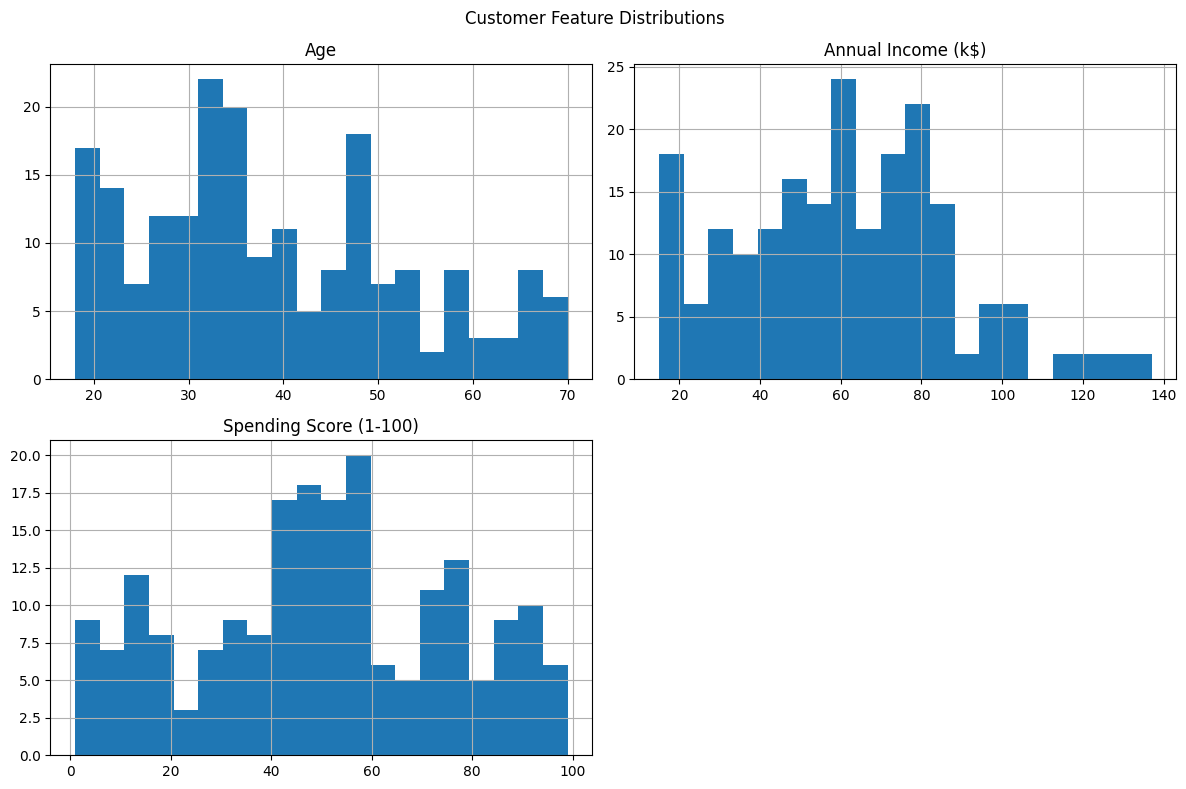

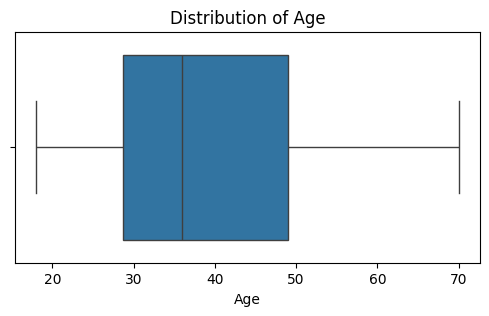

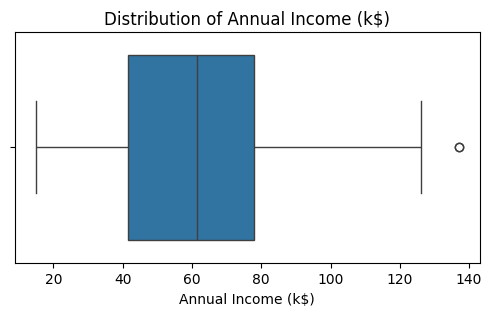

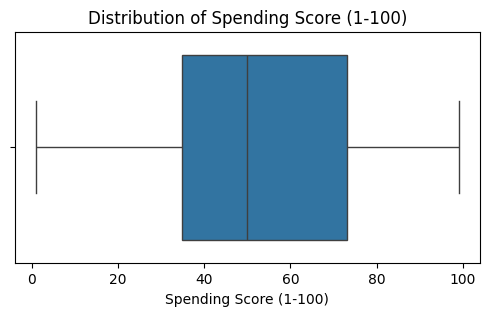

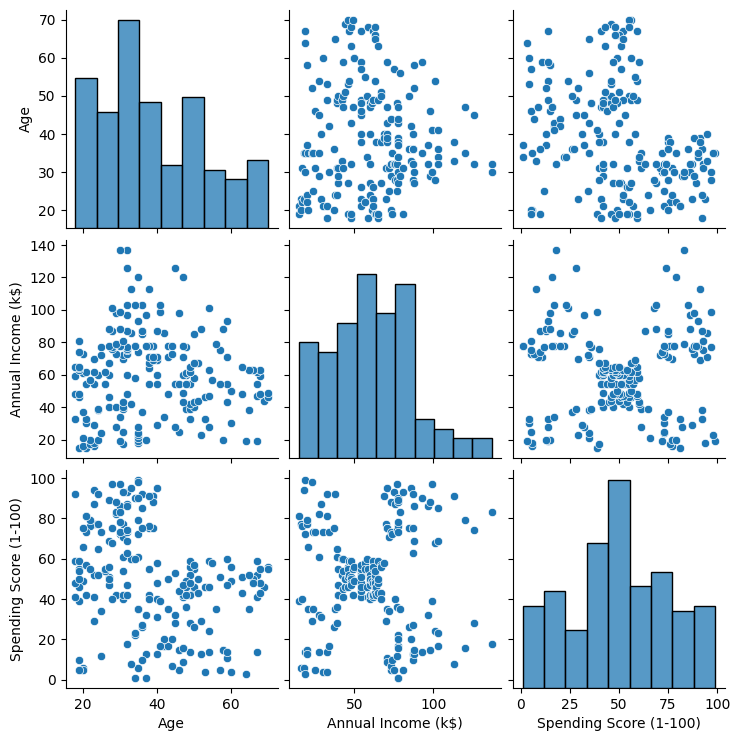

Gender
Female    112
Male       88
Name: count, dtype: int64


In [5]:
# STEP 2: Explore the numerical features

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# Histograms show feature distributions
df[features].hist(bins=20, figsize=(12, 8))
plt.suptitle("Customer Feature Distributions")
plt.tight_layout()
plt.show()

# Boxplots help identify unusual values
for feature in features:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[feature])
    plt.title(f"Distribution of {feature}")
    plt.show()

# Pairplot shows relationships between numerical features
sns.pairplot(df[features], diag_kind="hist")
plt.show()

# Check gender distribution, if available
if "Gender" in df.columns:
    print(df["Gender"].value_counts())

In [6]:
# STEP 3: Select the two main clustering features

features_2d = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features_2d].copy()

# Handle missing values if present
X = X.fillna(X.median())

# Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)
print("\nScaled feature means:", X_scaled.mean(axis=0))
print("Scaled feature standard deviations:",
      X_scaled.std(axis=0))

Original feature shape: (200, 2)
Scaled feature shape: (200, 2)

Scaled feature means: [-2.13162821e-16 -1.46549439e-16]
Scaled feature standard deviations: [1. 1.]


In [9]:
# Alternative experiment: include age

features_3d = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X3 = df[features_3d].copy()
X3 = X3.fillna(X3.median())

scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3)

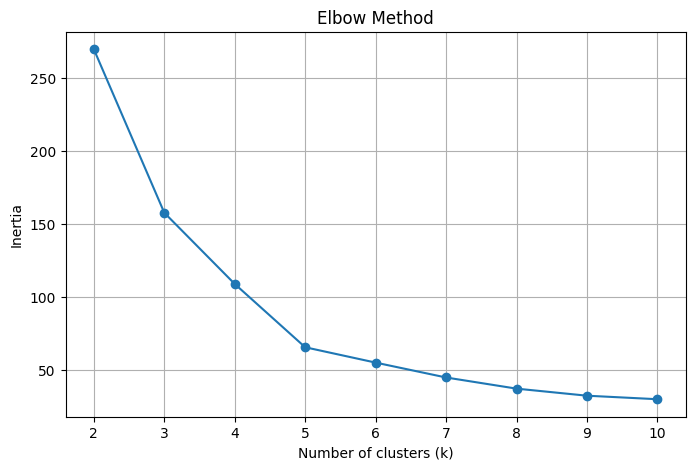

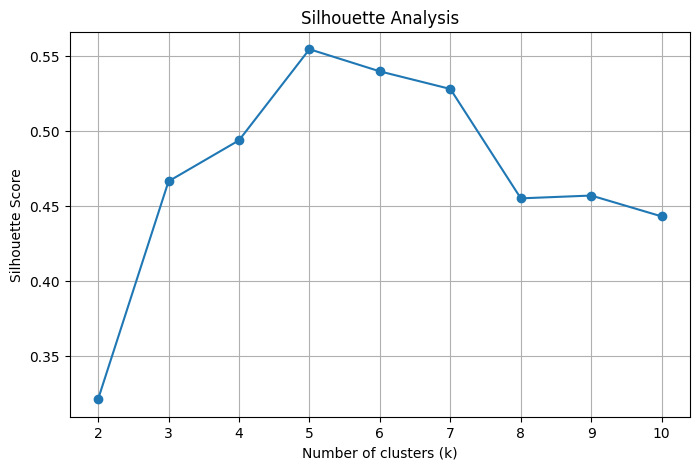

In [10]:
# STEP 4: Evaluate different numbers of clusters

k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:

    # Train K-Means for the current number of clusters
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    # Store the two evaluation measures
    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Plot inertia (elbow method)
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.grid(True)
plt.show()

In [11]:
# STEP 5A: K-Means

chosen_k = 5  # Revisit after examining Step 4

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# STEP 5B: Agglomerative hierarchical clustering

hierarchical = AgglomerativeClustering(
    n_clusters=chosen_k,
    linkage="ward"
)

df["Hierarchical_Cluster"] = (
    hierarchical.fit_predict(X_scaled)
)

# STEP 5C: DBSCAN

dbscan = DBSCAN(
    eps=0.35,
    min_samples=5
)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

# Display cluster sizes
for column in [
    "KMeans_Cluster",
    "Hierarchical_Cluster",
    "DBSCAN_Cluster"
]:
    print(f"\n{column}")
    print(df[column].value_counts().sort_index())


KMeans_Cluster
KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Hierarchical_Cluster
Hierarchical_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

DBSCAN_Cluster
DBSCAN_Cluster
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64


In [12]:
# STEP 6: Evaluate cluster separation

def evaluate_clusters(X, labels, model_name):
    labels = np.asarray(labels)

    # DBSCAN uses -1 to represent noise
    if model_name == "DBSCAN":
        mask = labels != -1
        X_eval = X[mask]
        labels_eval = labels[mask]
        noise_count = int((~mask).sum())
    else:
        X_eval = X
        labels_eval = labels
        noise_count = 0

    number_of_clusters = len(np.unique(labels_eval))

    result = {
        "Model": model_name,
        "Clusters": number_of_clusters,
        "Noise points": noise_count,
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan
    }

    if (
        number_of_clusters >= 2
        and number_of_clusters < len(labels_eval)
    ):
        result["Silhouette"] = silhouette_score(
            X_eval, labels_eval
        )
        result["Davies-Bouldin"] = davies_bouldin_score(
            X_eval, labels_eval
        )

    return result


comparison = pd.DataFrame([
    evaluate_clusters(X_scaled, df["KMeans_Cluster"], "K-Means"),
    evaluate_clusters(
        X_scaled, df["Hierarchical_Cluster"], "Hierarchical"
    ),
    evaluate_clusters(
        X_scaled, df["DBSCAN_Cluster"], "DBSCAN"
    )
])

print(comparison.round(4))

          Model  Clusters  Noise points  Silhouette  Davies-Bouldin
0       K-Means         5             0      0.5547          0.5722
1  Hierarchical         5             0      0.5538          0.5779
2        DBSCAN         6            23      0.5577          0.5106


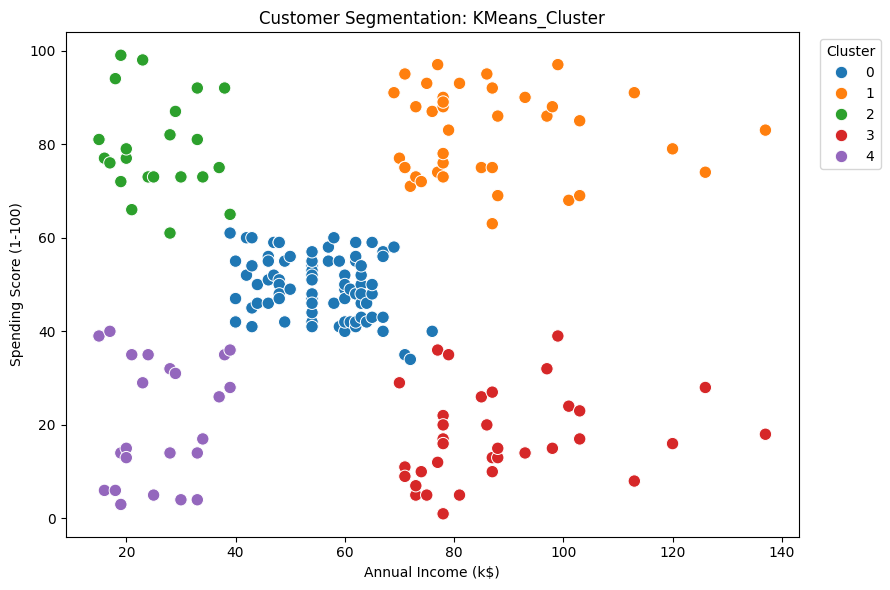

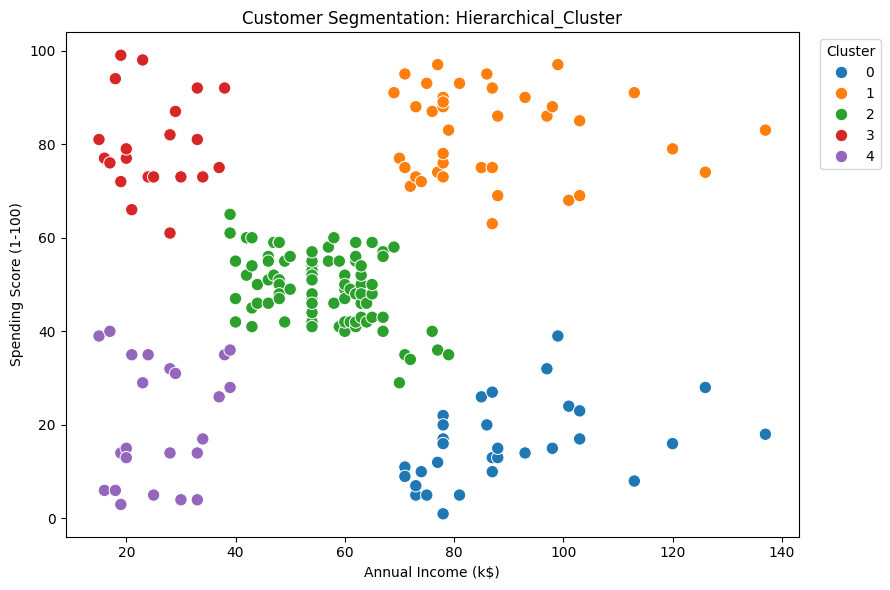

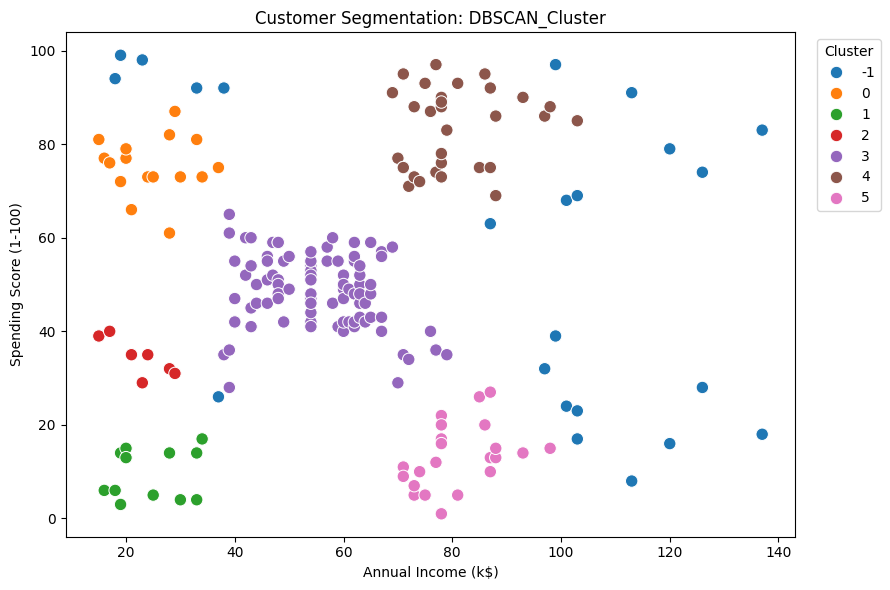

K-Means centroids in original units:
   Annual Income (k$)  Spending Score (1-100)
0               55.30                   49.52
1               86.54                   82.13
2               25.73                   79.36
3               88.20                   17.11
4               26.30                   20.91


In [13]:
# STEP 7: Visualize each clustering result

cluster_columns = [
    "KMeans_Cluster",
    "Hierarchical_Cluster",
    "DBSCAN_Cluster"
]

for cluster_column in cluster_columns:

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x="Annual Income (k$)",
        y="Spending Score (1-100)",
        hue=cluster_column,
        palette="tab10",
        s=80
    )

    plt.title(f"Customer Segmentation: {cluster_column}")
    plt.legend(
        title="Cluster",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()
    plt.show()

# Display K-Means centroids in original units
centroids = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features_2d
)

print("K-Means centroids in original units:")
print(centroids.round(2))

In [14]:
# STEP 8: Summarize each K-Means segment

profile = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
)

profile["Customer_Percentage"] = (
    profile["Customer_Count"] / len(df) * 100
)

print(profile.round(2))

                Customer_Count  Average_Age  Average_Income  Average_Spending  \
KMeans_Cluster                                                                  
0                           81        42.72           55.30             49.52   
1                           39        32.69           86.54             82.13   
2                           22        25.27           25.73             79.36   
3                           35        41.11           88.20             17.11   
4                           23        45.22           26.30             20.91   

                Customer_Percentage  
KMeans_Cluster                       
0                              40.5  
1                              19.5  
2                              11.0  
3                              17.5  
4                              11.5  


In [15]:
# STEP 9: Test whether age adds useful segmentation information

kmeans_3d = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

labels_3d = kmeans_3d.fit_predict(X3_scaled)

print(
    "Two-feature silhouette:",
    round(
        silhouette_score(
            X_scaled, df["KMeans_Cluster"]
        ), 4
    )
)

print(
    "Three-feature silhouette:",
    round(silhouette_score(X3_scaled, labels_3d), 4)
)

df["KMeans_3Feature_Cluster"] = labels_3d

profile_3d = df.groupby("KMeans_3Feature_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
)

print(profile_3d.round(2))

Two-feature silhouette: 0.5547
Three-feature silhouette: 0.4166
                         Customer_Count  Average_Age  Average_Income  \
KMeans_3Feature_Cluster                                                
0                                    20        46.25           26.75   
1                                    54        25.19           41.09   
2                                    40        32.88           86.10   
3                                    39        39.87           86.10   
4                                    47        55.64           54.38   

                         Average_Spending  
KMeans_3Feature_Cluster                    
0                                   18.35  
1                                   62.24  
2                                   81.53  
3                                   19.36  
4                                   48.85  


In [16]:
# STEP 10: Generate preliminary segment descriptions

income_median = df["Annual Income (k$)"].median()
spending_median = df["Spending Score (1-100)"].median()

def segment_description(row):

    high_income = row["Average_Income"] >= income_median
    high_spending = row["Average_Spending"] >= spending_median

    if high_income and high_spending:
        return "Higher income / higher spending"

    elif high_income and not high_spending:
        return "Higher income / lower spending"

    elif not high_income and high_spending:
        return "Lower income / higher spending"

    else:
        return "Lower income / lower spending"


profile_reset = profile.reset_index()

profile_reset["Segment_Description"] = profile_reset.apply(
    segment_description,
    axis=1
)

print(
    profile_reset[
        [
            "KMeans_Cluster",
            "Customer_Count",
            "Average_Income",
            "Average_Spending",
            "Segment_Description"
        ]
    ]
)

   KMeans_Cluster  Customer_Count  Average_Income  Average_Spending  \
0               0              81       55.296296         49.518519   
1               1              39       86.538462         82.128205   
2               2              22       25.727273         79.363636   
3               3              35       88.200000         17.114286   
4               4              23       26.304348         20.913043   

               Segment_Description  
0    Lower income / lower spending  
1  Higher income / higher spending  
2   Lower income / higher spending  
3   Higher income / lower spending  
4    Lower income / lower spending  


In [17]:
# STEP 11: Export results for the report

from pathlib import Path

output_dir = Path("customer_segmentation_outputs")
output_dir.mkdir(exist_ok=True)

# Save customer records and their cluster assignments
df.to_csv(
    output_dir / "customers_with_clusters.csv",
    index=False
)

# Save the segment profile table
profile.to_csv(
    output_dir / "kmeans_segment_profiles.csv"
)

# Save the algorithm comparison
comparison.to_csv(
    output_dir / "clustering_model_comparison.csv",
    index=False
)

# Save centroids
centroids.to_csv(
    output_dir / "kmeans_centroids.csv",
    index=False
)

print("All tables saved to:", output_dir.resolve())

All tables saved to: /content/customer_segmentation_outputs
